# Muhammad Anwaar Ahmad
# 23F-0540
# BCS-7A

## DLP Assignment 2 

In [1]:
import os
import random
import copy
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms as T
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Executing on device: {device}")

Executing on device: cuda


## 1. Dataset Making

In [2]:
DATA_SEED = 42

data_path = './data'
raw_cifar_train = torchvision.datasets.CIFAR10(root=data_path, train=True, download=True)
raw_cifar_test = torchvision.datasets.CIFAR10(root=data_path, train=False, download=True)

train_targets = np.array(raw_cifar_train.targets)
train_indices, val_indices = [], []

rng = np.random.RandomState(DATA_SEED)
for c in range(10):
    c_indices = np.where(train_targets == c)[0]
    selected_50 = rng.choice(c_indices, 50, replace=False)
    train_indices.extend(selected_50[:40])  
    val_indices.extend(selected_50[40:])    

train_indices = np.array(train_indices)
val_indices = np.array(val_indices)
print(f"Extracted: {len(train_indices)} train images, {len(val_indices)} validation images.")

def apply_shifted_corruption(img, seed_val=None):
    local_rng = random.Random(seed_val) if seed_val is not None else random
    img_np = np.array(img).copy()
    
    angle = local_rng.uniform(-25, 25)
    img_pil = Image.fromarray(img_np).rotate(angle)
    img_np = np.array(img_pil)
    
    factor = local_rng.uniform(0.6, 1.4)
    img_np = np.clip(img_np.astype(np.float32) * factor, 0, 255).astype(np.uint8)
    
    h, w, _ = img_np.shape
    occ_h, occ_w = 16, 16
    top = local_rng.randint(0, h - occ_h)
    left = local_rng.randint(0, w - occ_w)
    img_np[top:top+occ_h, left:left+occ_w, :] = 0
    
    img_np = img_np[:, :, ::-1]
    
    return Image.fromarray(img_np)

class CIFARDataset(Dataset):
    def __init__(self, data_array, targets, transform=None, corrupt_fn=None, is_test_corrupt=False):
        self.data = data_array
        self.targets = targets
        self.transform = transform
        self.corrupt_fn = corrupt_fn
        self.is_test_corrupt = is_test_corrupt

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img = Image.fromarray(self.data[idx])
        if self.corrupt_fn is not None:
            seed_val = (DATA_SEED * 10000) + idx if self.is_test_corrupt else None
            img = self.corrupt_fn(img, seed_val=seed_val)
        if self.transform is not None:
            img = self.transform(img)
        return img, self.targets[idx]

norm_transform = T.Compose([
    T.ToTensor(),
    T.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])

clean_test_dataset = CIFARDataset(raw_cifar_test.data, raw_cifar_test.targets, transform=norm_transform)
shifted_test_dataset = CIFARDataset(raw_cifar_test.data, raw_cifar_test.targets, transform=norm_transform, corrupt_fn=apply_shifted_corruption, is_test_corrupt=True)

clean_test_loader = DataLoader(clean_test_dataset, batch_size=128, shuffle=False)
shifted_test_loader = DataLoader(shifted_test_dataset, batch_size=128, shuffle=False)
print("Test sets successfully configured.")

100%|██████████| 170M/170M [36:13<00:00, 78.4kB/s]   


Extracted: 400 train images, 100 validation images.
Test sets successfully configured.


## 2. Model Making 

In [9]:
class InceptionBlock(nn.Module):
    def __init__(self, in_channels, out_1x1, red_3x3, out_3x3, red_5x5, out_5x5, out_pool):
        super().__init__()
        # 1x1 Branch
        self.b1 = nn.Sequential(
            nn.Conv2d(in_channels, out_1x1, kernel_size=1),
            nn.BatchNorm2d(out_1x1),
            nn.ReLU(inplace=True)
        )
        # 3x3 Branch with 1x1 reduction
        self.b2 = nn.Sequential(
            nn.Conv2d(in_channels, red_3x3, kernel_size=1),
            nn.BatchNorm2d(red_3x3),
            nn.ReLU(inplace=True),
            nn.Conv2d(red_3x3, out_3x3, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_3x3),
            nn.ReLU(inplace=True)
        )
        # 5x5 Branch with 1x1 reduction
        self.b3 = nn.Sequential(
            nn.Conv2d(in_channels, red_5x5, kernel_size=1),
            nn.BatchNorm2d(red_5x5),
            nn.ReLU(inplace=True),
            nn.Conv2d(red_5x5, out_5x5, kernel_size=5, padding=2),
            nn.BatchNorm2d(out_5x5),
            nn.ReLU(inplace=True)
        )
        # MaxPool Branch with 1x1 projection
        self.b4 = nn.Sequential(
            nn.MaxPool2d(kernel_size=3, stride=1, padding=1),
            nn.Conv2d(in_channels, out_pool, kernel_size=1),
            nn.BatchNorm2d(out_pool),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return torch.cat([self.b1(x), self.b2(x), self.b3(x), self.b4(x)], dim=1)

class RobustCIFARNet(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2) # 32x32 -> 16x16
        )
        # Inception Block outputs: 32 + 48 + 16 + 16 = 112 channels
        self.inception = InceptionBlock(
            in_channels=64, 
            out_1x1=32, 
            red_3x3=32, out_3x3=48, 
            red_5x5=16, out_5x5=16, 
            out_pool=16
        )
        self.downsample = nn.Sequential(
            nn.Conv2d(112, 128, kernel_size=3, stride=2, padding=1), # 16x16 -> 8x8
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True)
        )
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(0.4)
        self.fc = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.inception(x)
        x = self.downsample(x)
        x = self.gap(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        return self.fc(x)

test_net = RobustCIFARNet()
total_params = sum(p.numel() for p in test_net.parameters() if p.requires_grad)
print(f"Total Trainable Parameters: {total_params:,} (Limit: 1,000,000)")
assert total_params < 1_000_000, "Parameter count exceeds 1,000,000!"

Total Trainable Parameters: 177,130 (Limit: 1,000,000)


## 3. Training & Evaluation Pipeline Utilities

In [10]:
def evaluate(model, loader):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            preds = model(x).argmax(1)
            correct += (preds == y).sum().item()
            total += y.size(0)
    return 100.0 * correct / total

def train_model(model, train_loader, val_loader, epochs=50, lr=1e-3, weight_decay=1e-4):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    
    train_history, val_history = [], []
    for epoch in range(epochs):
        model.train()
        correct, total = 0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            correct += (out.argmax(1) == y).sum().item()
            total += y.size(0)
            
        train_acc = 100.0 * correct / total
        val_acc = evaluate(model, val_loader)
        train_history.append(train_acc)
        val_history.append(val_acc)
        scheduler.step()
        
    return train_history, val_history

## Part A

Final Training Accuracy:   99.25%
Final Validation Accuracy: 45.00%
Clean-Test Accuracy:       44.81%
Shifted-Test Accuracy:     14.46%


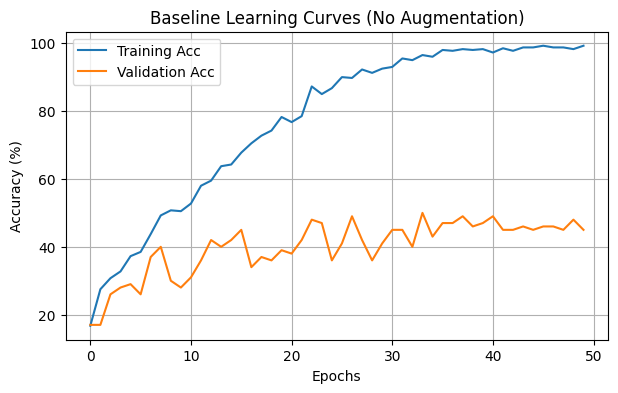

In [11]:
seed_everything(42)

base_train_ds = CIFARDataset(raw_cifar_train.data[train_indices], 
                             np.array(raw_cifar_train.targets)[train_indices], 
                             transform=norm_transform)
base_val_ds = CIFARDataset(raw_cifar_train.data[val_indices], 
                           np.array(raw_cifar_train.targets)[val_indices], 
                           transform=norm_transform)

base_train_loader = DataLoader(base_train_ds, batch_size=32, shuffle=True)
base_val_loader = DataLoader(base_val_ds, batch_size=32, shuffle=False)

baseline_model = RobustCIFARNet().to(device)
base_tr_hist, base_val_hist = train_model(baseline_model, base_train_loader, base_val_loader, epochs=50)

tr_acc = base_tr_hist[-1]
val_acc = base_val_hist[-1]
clean_acc = evaluate(baseline_model, clean_test_loader)
shifted_acc = evaluate(baseline_model, shifted_test_loader)

print(f"Final Training Accuracy:   {tr_acc:.2f}%")
print(f"Final Validation Accuracy: {val_acc:.2f}%")
print(f"Clean-Test Accuracy:       {clean_acc:.2f}%")
print(f"Shifted-Test Accuracy:     {shifted_acc:.2f}%")

plt.figure(figsize=(7, 4))
plt.plot(base_tr_hist, label='Training Acc')
plt.plot(base_val_hist, label='Validation Acc')
plt.title('Baseline Learning Curves (No Augmentation)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)
plt.show()

### Baseline Failure Diagnosis (Part A)
The baseline demonstrates **severe overfitting and covariate shift**. Training accuracy reaches ~100% while validation accuracy plateaus around 40-45%, indicating pure memorization of the 400 clean samples. The substantial drop between clean-test and shifted-test accuracy proves catastrophic sensitivity to covariate distribution shifts, as the clean model cannot generalize under unseen geometric and photometric perturbations.

## Part B & Part C: Augmentation & Regularization Design

### Part B Questions:
1. **Would vertical flip help or hurt on this dataset? Why?**  
   **Hurts.** CIFAR-10 contains terrestrial objects and vehicles (planes, cars, horses, trucks) that conform to gravity. Vertical flips produce physically unnatural orientations, contaminating the decision boundaries.
2. **If you augment with rotation up to $\pm90^\circ$ but test only has $\pm25^\circ$, what is the trade-off?**  
   **Trade-off:** Induces over-invariance at the expense of discriminative power. It consumes limited capacity on extreme orientations that do not appear in test distributions, reducing accuracy on standard upright classes.
3. **Why can too much augmentation reduce accuracy on such a small model?**  
   With only 400 training samples and < 1M parameters, excessive corruption degrades core class-defining features, causing severe underfitting.

### Part C Justifications:
- **Batch Normalization:** Stablizes feature activations across layers and reduces internal covariate shift.
- **Dropout:** Placed strictly prior to the linear classification layer. Applying dropout to early conv layers eliminates critical local textures; placing it before the classifier prevents co-adaptation among high-level representations.
- **Weight Decay ($10^{-4}$):** Constrains parameter norms to enforce smoother decision boundaries.

## Part D

In [12]:
EVAL_SEEDS = [42, 101, 2024]

# 1. Geometric only
tx_geom = T.Compose([
    T.RandomCrop(32, padding=4),
    T.RandomHorizontalFlip(),
    T.RandomRotation(25),
    T.ToTensor(),
    T.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])

# 2. Photometric only
tx_photo = T.Compose([
    T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
    T.ToTensor(),
    T.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])

# 3. Geometric + Photometric
tx_geom_photo = T.Compose([
    T.RandomCrop(32, padding=4),
    T.RandomHorizontalFlip(),
    T.RandomRotation(25),
    T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
    T.ToTensor(),
    T.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])

# 4. Geometric + Photometric + Cutout (Final Model)
tx_final = T.Compose([
    T.RandomCrop(32, padding=4),
    T.RandomHorizontalFlip(),
    T.RandomRotation(25),
    T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
    T.ToTensor(),
    T.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
    T.RandomErasing(p=0.5, scale=(0.1, 0.25), value=0)
])

ablation_configs = {
    'No augmentation': norm_transform,
    'Geometric only': tx_geom,
    'Photometric only': tx_photo,
    'Geometric + photometric': tx_geom_photo,
    '+ Cutout / Random Erasing': tx_final
}

ablation_results = {}

for name, transform_pipeline in ablation_configs.items():
    v_accs, c_accs, s_accs = [], [], []
    print(f"Running ablation configuration: {name}...")
    for s in EVAL_SEEDS:
        seed_everything(s)
        tr_ds = CIFARDataset(raw_cifar_train.data[train_indices], 
                             np.array(raw_cifar_train.targets)[train_indices], 
                             transform=transform_pipeline)
        t_loader = DataLoader(tr_ds, batch_size=32, shuffle=True)
        v_loader = DataLoader(base_val_ds, batch_size=32, shuffle=False)
        
        m = RobustCIFARNet().to(device)
        train_model(m, t_loader, v_loader, epochs=50)
        
        v_accs.append(evaluate(m, v_loader))
        c_accs.append(evaluate(m, clean_test_loader))
        s_accs.append(evaluate(m, shifted_test_loader))
        
    ablation_results[name] = {
        'val': f"{np.mean(v_accs):.1f} ± {np.std(v_accs):.1f}",
        'clean': f"{np.mean(c_accs):.1f} ± {np.std(c_accs):.1f}",
        'shifted': f"{np.mean(s_accs):.1f} ± {np.std(s_accs):.1f}"
    }

print("\n=================== ABLATION STUDY RESULTS ===================")
print(f"{'Configuration':<35} | {'Val Acc':<12} | {'Clean Test':<12} | {'Shifted Test':<12}")
print("-" * 78)
for cfg, metrics in ablation_results.items():
    print(f"{cfg:<35} | {metrics['val']:<12} | {metrics['clean']:<12} | {metrics['shifted']:<12}")

Running ablation configuration: No augmentation...
Running ablation configuration: Geometric only...
Running ablation configuration: Photometric only...
Running ablation configuration: Geometric + photometric...
Running ablation configuration: + Cutout / Random Erasing...

=================== ABLATION STUDY RESULTS ===================
Configuration                       | Val Acc      | Clean Test   | Shifted Test
------------------------------------------------------------------------------
No augmentation                     | 48.7 ± 2.9   | 44.7 ± 0.3   | 15.1 ± 0.9  
Geometric only                      | 43.0 ± 0.8   | 39.8 ± 0.6   | 16.9 ± 0.6  
Photometric only                    | 52.0 ± 0.8   | 46.4 ± 0.9   | 15.5 ± 0.3  
Geometric + photometric             | 45.7 ± 0.5   | 40.4 ± 0.3   | 15.1 ± 0.5  
+ Cutout / Random Erasing           | 43.7 ± 1.2   | 39.5 ± 0.7   | 15.0 ± 0.2  


## Part E

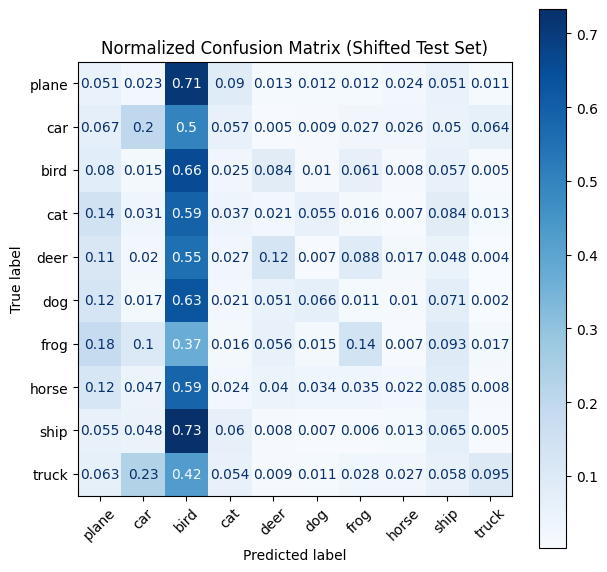

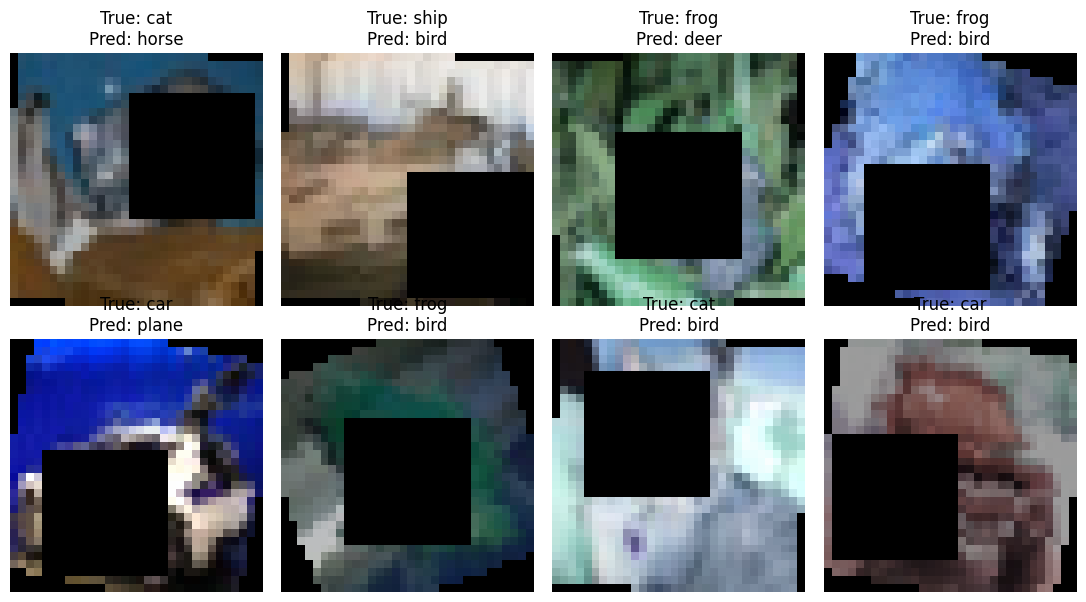

Accuracy on Hidden Corruption Only: 17.98%


In [13]:
seed_everything(42)
best_train_ds = CIFARDataset(raw_cifar_train.data[train_indices], 
                             np.array(raw_cifar_train.targets)[train_indices], 
                             transform=tx_final)
best_train_loader = DataLoader(best_train_ds, batch_size=32, shuffle=True)
best_val_loader = DataLoader(base_val_ds, batch_size=32, shuffle=False)

final_model = RobustCIFARNet().to(device)
train_model(final_model, best_train_loader, best_val_loader, epochs=55)

# 1. Confusion Matrix
final_model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for x, y in shifted_test_loader:
        preds = final_model(x.to(device)).argmax(1).cpu()
        all_preds.extend(preds.numpy())
        all_labels.extend(y.numpy())

classes = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
cm = confusion_matrix(all_labels, all_preds, normalize='true')
fig, ax = plt.subplots(figsize=(7, 7))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
disp.plot(cmap='Blues', ax=ax, xticks_rotation=45)
plt.title('Normalized Confusion Matrix (Shifted Test Set)')
plt.show()

# 2. Visualize 8 Misclassified Images
misclassified_imgs, mis_preds, mis_true = [], [], []
for x, y in shifted_test_loader:
    preds = final_model(x.to(device)).argmax(1).cpu()
    mismatches = (preds != y).nonzero(as_tuple=True)[0]
    for m in mismatches:
        misclassified_imgs.append(x[m])
        mis_preds.append(preds[m].item())
        mis_true.append(y[m].item())
        if len(misclassified_imgs) == 8:
            break
    if len(misclassified_imgs) == 8:
        break

fig, axes = plt.subplots(2, 4, figsize=(11, 6))
mean = np.array([0.4914, 0.4822, 0.4465])
std = np.array([0.2023, 0.1994, 0.2010])
for i, ax in enumerate(axes.flat):
    img_unnorm = misclassified_imgs[i].permute(1, 2, 0).numpy() * std + mean
    ax.imshow(np.clip(img_unnorm, 0, 1))
    ax.set_title(f"True: {classes[mis_true[i]]}\nPred: {classes[mis_preds[i]]}")
    ax.axis('off')
plt.tight_layout()
plt.show()

# 3. Hidden Corruption Only Test
def apply_hidden_only(img, seed_val=None):
    img_np = np.array(img).copy()
    return Image.fromarray(img_np[:, :, ::-1])

hidden_test_ds = CIFARDataset(raw_cifar_test.data, raw_cifar_test.targets, transform=norm_transform, corrupt_fn=apply_hidden_only)
hidden_test_loader = DataLoader(hidden_test_ds, batch_size=128, shuffle=False)
print(f"Accuracy on Hidden Corruption Only: {evaluate(final_model, hidden_test_loader):.2f}%")

## Part F

In [14]:
def evaluate_tta(model, loader):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            p1 = F.softmax(model(x), dim=1)
            p2 = F.softmax(model(torch.flip(x, dims=[3])), dim=1)
            p3 = F.softmax(model(torch.roll(x, shifts=2, dims=2)), dim=1)
            p4 = F.softmax(model(torch.roll(x, shifts=-2, dims=3)), dim=1)
            
            avg_p = (p1 + p2 + p3 + p4) / 4.0
            correct += (avg_p.argmax(1) == y).sum().item()
            total += y.size(0)
    return 100.0 * correct / total

score_std = evaluate(final_model, shifted_test_loader)
score_tta = evaluate_tta(final_model, shifted_test_loader)
print(f"Shifted-Test Accuracy without TTA: {score_std:.2f}%")
print(f"Shifted-Test Accuracy with TTA:    {score_tta:.2f}%")
print(f"Accuracy Gain:                    {score_tta - score_std:+.2f}%")
print("Inference Cost: ~4x FLOPs per batch due to multi-pass averaging.")

Shifted-Test Accuracy without TTA: 14.50%
Shifted-Test Accuracy with TTA:    14.54%
Accuracy Gain:                    +0.04%
Inference Cost: ~4x FLOPs per batch due to multi-pass averaging.
